# Movable-fin attitude stabilization of a Falcon 9-inspired rocket

**AE 370: Group Project 1**  
**Authors:** Bharat Rajesh, Thomas Theodor, Jorgen Nelson, Carlos Avila

## Premise

How do maximum fin deflection and actuator response time affect the recovery time and fin effort of a disturbed rocket's three-dimensional attitude?

SpaceX describes Falcon 9 as approximately 3.7 m in diameter, with four grid fins near the interstage that orient the first stage during reentry [1,2]. We borrow this size and four-fin architecture as the motivation for a simplified attitude model. Our mass, inertia approximation, aerodynamic coefficients, actuator dynamics, and controller are study assumptions rather than published Falcon 9 performance data.

The study integrates a nonlinear initial value problem with ten states. It retains three-dimensional rotational coupling and finite actuator response while holding the flight condition fixed. The resulting recovery and effort metrics require the full time-dependent numerical solution. Exact solutions are used only for deliberately simplified verification cases.

The nominal simulation recovers in 7.27 s. All 49 combinations in the chosen parameter grid recover within the 24 s simulation and the specified two-second confirmation window. These are predictions of the stated model.

## Model, assumptions, and initial value problem

The body axes are $x$ for roll, $y$ for pitch, and $z$ for yaw, consistent with SpaceX's axis naming [2, Sec. 4.1.2]. We place the origin at the center of mass. The fixed reference frame is aligned with the desired attitude, so the desired Euler angles are zero; zero pitch here does not mean that the real rocket is horizontal.

| Quantity | Value | Basis |
|---|---:|---|
| Body radius $r_b$ | $1.85\ \mathrm{m}$ | Half the rounded diameter in [1] |
| Number of fins | 4 | Architecture in [1,2] |
| Mass $m$ | $25{,}000\ \mathrm{kg}$ | Assumed reduced-mass stage |
| Uniform-shell length $L$ | $40\ \mathrm{m}$ | Assumed inertia geometry |
| Axial fin arm $\ell$ | $15\ \mathrm{m}$ | Assumed distance ahead of center of mass |
| Radial fin-force arm $a$ | $2.6\ \mathrm{m}$ | Assumed effective moment arm |
| Density $\rho$ | $0.9\ \mathrm{kg/m^3}$ | Chosen constant flight condition |
| Speed $V$ | $200\ \mathrm{m/s}$ | Chosen constant flight condition |
| Effective area per fin $A_f$ | $1.5\ \mathrm{m^2}$ | Assumed effective area |
| Force coefficient slope $C_{N\delta}$ | $2\ \mathrm{rad^{-1}}$ | Assumed linear coefficient |
| Rate damping $D$ | $\operatorname{diag}(10^4,3\times10^5,3\times10^5)$ | Assumed; entries in $\mathrm{N\,m\,s/rad}$ |
| Nominal actuator time constant $\tau_a$ | $0.15\ \mathrm{s}$ | Study parameter |
| Nominal fin limit $\delta_{\max}$ | $15^\circ$ | Study parameter |

The thin cylindrical shell approximation gives

$$
I_x=mr_b^2=85{,}562.5\ \mathrm{kg\,m^2},\qquad
I_y=I_z=m\left(\frac{L^2}{12}+\frac{r_b^2}{2}\right)
=3{,}376{,}114.58\ \mathrm{kg\,m^2}.
$$

Write $\mathsf I=\operatorname{diag}(I_x,I_y,I_z)$, $\boldsymbol\eta=(\phi,\theta,\psi)^T$, $\boldsymbol\omega=(p,q,r)^T$, and $\boldsymbol\delta=(\delta_1,\ldots,\delta_4)^T$. The state is

$$
\mathbf u=(\phi,\theta,\psi,p,q,r,\delta_1,\delta_2,\delta_3,\delta_4)^T.
$$

All calculations use radians and seconds. The initial condition is

$$
\boldsymbol\eta(0)=(12,-10,8)^\circ,\qquad
\boldsymbol\omega(0)=(4,-3,2)^\circ/\mathrm{s},\qquad
\boldsymbol\delta(0)=\mathbf0.
$$

For a 3-2-1 Euler rotation, $R=R_z(\psi)R_y(\theta)R_x(\phi)$ maps body vectors into the reference frame. Its angle-rate relations are [4]

$$
\begin{aligned}
\dot\phi&=p+(q\sin\phi+r\cos\phi)\tan\theta,\\
\dot\theta&=q\cos\phi-r\sin\phi,\\
\dot\psi&=\frac{q\sin\phi+r\cos\phi}{\cos\theta}.
\end{aligned}
$$

We monitor pitch to stay away from the Euler-angle singularity at $\cos\theta=0$.

### Idealized fin forces and rigid-body motion

Choose fin locations $\beta_j=0,\pi/2,\pi,3\pi/2$. Our assumed tangential force model is

$$
\mathbf r_j=(\ell,a\cos\beta_j,a\sin\beta_j)^T,\qquad
\mathbf F_j=K_f\delta_j(0,-\sin\beta_j,\cos\beta_j)^T,
$$

$$
K_f=\tfrac12\rho V^2 A_f C_{N\delta}=54{,}000\ \mathrm{N/rad}.
$$

Taking $\mathbf r_j\times\mathbf F_j$ gives $K_f\delta_j(a,-\ell\cos\beta_j,-\ell\sin\beta_j)^T$, hence

$$
B=K_f\begin{bmatrix}
a&a&a&a\\-\ell&0&\ell&0\\0&-\ell&0&\ell
\end{bmatrix},\qquad
\mathbf M=B\boldsymbol\delta-D\boldsymbol\omega.
$$

The principal-axis rigid-body equations follow angular-momentum balance [3, Eqs. (5), (9)--(11)]:

$$
\mathsf I\dot{\boldsymbol\omega}
+\boldsymbol\omega\times(\mathsf I\boldsymbol\omega)=\mathbf M.
$$

Thus

$$
\dot p=\frac{M_x+(I_y-I_z)qr}{I_x},\quad
\dot q=\frac{M_y+(I_z-I_x)rp}{I_y},\quad
\dot r=\frac{M_z+(I_x-I_y)pq}{I_z}.
$$

Although $I_y=I_z$ eliminates the $qr$ term in the roll equation, the pitch/yaw coupling and nonlinear angle kinematics remain.

### Assumed feedback and actuator law

We choose a proportional/derivative moment request

$$
\mathbf M_{\rm req}=-K_p\boldsymbol\eta-K_d\boldsymbol\omega,\qquad
K_p=\operatorname{diag}(I_i\omega_{n,i}^2),\quad
K_d=\operatorname{diag}(2I_i\omega_{n,i}),
$$

with $\boldsymbol\omega_n=(1.3,0.7,0.7)^T\ \mathrm{rad/s}$. These gains are chosen to set a convenient recovery time scale, not to reproduce a SpaceX controller. Define

$$
G=\begin{bmatrix}1&-1&0\\1&0&-1\\1&1&0\\1&0&1\end{bmatrix},\quad
E_0=K_f\operatorname{diag}(4a,2\ell,2\ell),\quad H=GE_0^{-1}.
$$

Since $B_0G=E_0$, the nominal allocation satisfies $B_0H=\mathsf I_3$. The fin commands and states obey, componentwise,

$$
\boldsymbol\delta_{\rm cmd}
=\delta_{\max}\tanh\left(\frac{H\mathbf M_{\rm req}}{\delta_{\max}}\right),\qquad
\dot{\boldsymbol\delta}=
\frac{\boldsymbol\delta_{\rm cmd}-\boldsymbol\delta}{\tau_a}.
$$

This is a smooth bounded command with first-order actuator lag. It has no separately imposed slew-rate limit. The controller and nominal allocator remain fixed throughout all comparisons.

Together these equations define $\dot{\mathbf u}=f(\mathbf u,t)$ over $0\le t\le24\ \mathrm{s}$. The model is autonomous because the chosen flight condition and reference attitude are constant.

We neglect translation, varying atmosphere, fuel motion, flexibility, winds, sensor noise, engine/thruster torques, and zero-deflection static aerodynamic restoring moments. The frozen flight condition isolates actuator and fin-authority effects; it is not a complete descent simulation.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

m, L, rb = 25000., 40., 1.85
a, ell = 2.6, 15.
rho, V, Af, CNd = 0.9, 200., 1.5, 2.
I0 = np.array([m*rb**2, m*(L**2/12 + rb**2/2),
               m*(L**2/12 + rb**2/2)])
D0 = np.array([1.e4, 3.e5, 3.e5])
Kf = 0.5*rho*V**2*Af*CNd
B0 = Kf*np.array([[a,a,a,a],[-ell,0,ell,0],[0,-ell,0,ell]])
G = np.array([[1,-1,0],[1,0,-1],[1,1,0],[1,0,1]])
wn = np.array([1.3,0.7,0.7])
Kp, Kd = I0*wn**2, 2*I0*wn
H = G / (Kf*np.array([4*a,2*ell,2*ell]))

def parameters(tau=.15, limit=15., force_scale=1., inertia_scale=1.,
               active=True, damping=True, inertia=None):
    return {'I': I0*inertia_scale if inertia is None else np.array(inertia),
            'D': D0.copy() if damping else np.zeros(3),
            'B': B0*force_scale, 'tau': tau,
            'limit': np.deg2rad(limit), 'active': active}

def rhs(u,t,P):
    phi,theta,psi,p,q,r = u[:6]
    s,c,ct = np.sin(phi),np.cos(phi),np.cos(theta)
    if abs(ct)<.15:
        raise ValueError('Motion is too close to the Euler pitch singularity.')
    angle_dot = np.array([p+(s*q+c*r)*np.tan(theta),
                          c*q-s*r,(s*q+c*r)/ct])
    w=u[3:6]
    moment=P['B']@u[6:]-P['D']*w
    rate_dot=(moment-np.cross(w,P['I']*w))/P['I']
    command=np.zeros(4)
    if P['active']:
        requested=-Kp*u[:3]-Kd*w
        command=P['limit']*np.tanh((H@requested)/P['limit'])
    fin_dot=(command-u[6:])/P['tau']
    return np.r_[angle_dot,rate_dot,fin_dot]

u0=np.r_[np.deg2rad([12.,-10.,8.,4.,-3.,2.]),np.zeros(4)]
P0=parameters()

## Numerical method and error

We use the explicit four-stage Runge--Kutta method from Lecture 10, Eq. (8) [5]. The integral form of the IVP is

$$
\mathbf u(t_k+h)=\mathbf u(t_k)+\int_{t_k}^{t_k+h} f(\mathbf u(t),t)\,dt.
$$

The lecture's interpolation approach approximates this integral using predicted slopes at the beginning, midpoint, and end of a step:

$$
\begin{aligned}
\mathbf y_1&=f(\mathbf u_k,t_k),\\
\mathbf y_2&=f(\mathbf u_k+\tfrac h2\mathbf y_1,t_k+\tfrac h2),\\
\mathbf y_3&=f(\mathbf u_k+\tfrac h2\mathbf y_2,t_k+\tfrac h2),\\
\mathbf y_4&=f(\mathbf u_k+h\mathbf y_3,t_k+h),\\
\mathbf u_{k+1}&=\mathbf u_k+\frac h6
(\mathbf y_1+2\mathbf y_2+2\mathbf y_3+\mathbf y_4).
\end{aligned}
$$

To check its error, start the step from the exact state and Taylor-expand the stages about that state. Their weighted average is

$$
\frac{\mathbf y_1+2\mathbf y_2+2\mathbf y_3+\mathbf y_4}{6}
=\dot{\mathbf u}(t_k)+\frac h2\ddot{\mathbf u}(t_k)
+\frac{h^2}{6}\mathbf u^{(3)}(t_k)
+\frac{h^3}{24}\mathbf u^{(4)}(t_k)+O(h^4).
$$

Multiplication by $h$ and addition of $\mathbf u(t_k)$ therefore match the exact time-Taylor expansion through $h^4$ [6]. If $\Phi_h$ denotes the RK4 step, its **step defect** is

$$
\mathbf d_{k+1}=\mathbf u(t_{k+1})-\Phi_h(\mathbf u(t_k),t_k)=O(h^5).
$$

Following Lecture 11's convention, divide by $h$ to define the **normalized truncation error**:

$$
\boldsymbol\tau_k=\frac{\mathbf d_{k+1}}h=O(h^4).
$$

With bounded smooth derivatives and stable propagation over a fixed interval, the accumulated error is $O(h^4)$ [6,7]. For example, an error bound of the form $E_{k+1}\le(1+Ch)E_k+C_dh^5$, starting from $E_0=0$, sums to $E_N=O(h^4)$ for fixed $Nh$.

The smooth $\tanh$ law and avoidance of the pitch singularity support these assumptions. We also check the order numerically; the scalar stability calculation below is a separate check.

Each RK4 step uses four evaluations of $f$ and no algebraic solve. Forward Euler uses one evaluation and first-order global accuracy [5,6]. We compare both at equal derivative-evaluation cost. NumPy supplies arithmetic, cross products, and eigenvalues; all time stepping below is implemented directly, without an outside IVP integrator.

In [ ]:
def integrate(f,u0,tf,h,method='RK4'):
    n=int(round(tf/h))
    if not np.isclose(n*h,tf):
        raise ValueError('Choose h so it divides tf.')
    t=np.linspace(0,tf,n+1)
    u=np.empty((n+1,len(u0)))
    u[0]=u0
    for k in range(n):
        y1=f(u[k],t[k])
        if method=='Euler':
            u[k+1]=u[k]+h*y1
        elif method=='RK4':
            y2=f(u[k]+h*y1/2,t[k]+h/2)
            y3=f(u[k]+h*y2/2,t[k]+h/2)
            y4=f(u[k]+h*y3,t[k]+h)
            u[k+1]=u[k]+h*(y1+2*y2+2*y3+y4)/6
        else:
            raise ValueError('Choose Euler or RK4.')
    return t,u

def rotation(angles):
    phi,theta,psi=angles
    cp,sp=np.cos(phi),np.sin(phi)
    ct,st=np.cos(theta),np.sin(theta)
    cs,ss=np.cos(psi),np.sin(psi)
    return np.array([[cs*ct,cs*st*sp-ss*cp,cs*st*cp+ss*sp],
        [ss*ct,ss*st*sp+cs*cp,ss*st*cp-cs*sp],[-st,ct*sp,ct*cp]])

## Independent implementation checks

A fine-step reference can reveal convergence without detecting an error shared by every run. We therefore also use geometry, exact special cases, and conservation laws.

1. Recompute every column of $B$ from $\mathbf r_j\times\mathbf F_j$ and confirm that $B$ has rank three.
2. Disable feedback and damping, excite one principal axis at a time, and let the fins decay with $\tau_a=0.3\ \mathrm{s}$. For $\boldsymbol\delta_0=0.01G_{:,i}$, $\omega_i(0)=0.01\ \mathrm{rad/s}$, and $\eta_i(0)=0$, define $a_0=(B\boldsymbol\delta_0)_i/I_i$. The exact solution is

$$
\boldsymbol\delta(t)=\boldsymbol\delta_0e^{-t/\tau_a},\quad
\omega_i(t)=0.01+a_0\tau_a(1-e^{-t/\tau_a}),
$$

$$
\eta_i(t)=0.01t+a_0\tau_a\left[t-\tau_a(1-e^{-t/\tau_a})\right].
$$

All other angular states remain zero. These exact solutions are obtained by integrating the exponential fin torque twice. For this check, states are scaled by $1\ \mathrm{rad}$ for angles/fins and $1\ \mathrm{rad/s}$ for rates before taking the maximum error; this is numerically the same as comparing their SI-valued components.

3. Set all external moments to zero and use unequal inertias $(2,3,4)\ \mathrm{kg\,m^2}$ to exercise every rotational coupling term. Rotational energy $E=\tfrac12\boldsymbol\omega^T\mathsf I\boldsymbol\omega$ and the reference-frame angular momentum $\mathbf H_R=R\mathsf I\boldsymbol\omega$ must be constant [3].

The exact-solution tests give observed orders approximately 4.03 for roll, pitch, and yaw. At $h=0.01\ \mathrm{s}$, the torque-free test has relative energy drift below $4\times10^{-15}$ and relative angular-momentum vector drift below $4\times10^{-13}$ in the checked run. Small variations at roundoff level are expected across machines.

Exact-solution orders: [4.03008308 4.03008288 4.03008288]


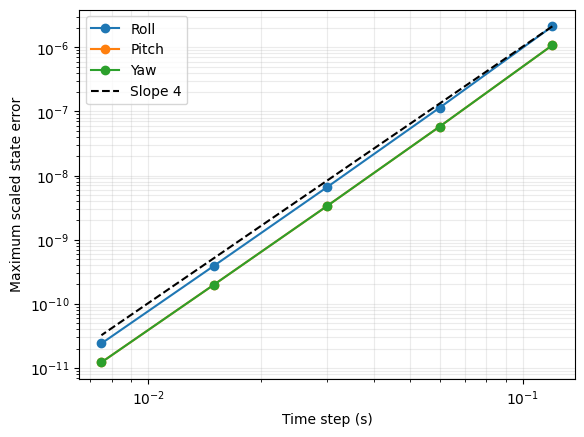

Relative energy drift: 3.76665996480121e-15
Relative inertial angular-momentum drift: 3.875666818198806e-13


In [ ]:
columns=[]
for beta in [0,np.pi/2,np.pi,3*np.pi/2]:
    position=np.array([ell,a*np.cos(beta),a*np.sin(beta)])
    force=Kf*np.array([0,-np.sin(beta),np.cos(beta)])
    columns.append(np.cross(position,force))
assert np.allclose(np.array(columns).T,B0)
assert np.linalg.matrix_rank(B0)==3

hs=np.array([.12,.06,.03,.015,.0075])
errors=np.zeros((3,len(hs)))
for axis in range(3):
    P=parameters(tau=.3,active=False,damping=False)
    start=np.zeros(10)
    start[3+axis]=.01
    start[6:]=.01*G[:,axis]
    a0=(P['B']@start[6:])[axis]/P['I'][axis]
    for j,h in enumerate(hs):
        t,u=integrate(lambda u,t:rhs(u,t,P),start,1.2,h)
        decay=np.exp(-t/P['tau'])
        exact=np.zeros_like(u)
        exact[:,6:]=decay[:,None]*start[6:]
        exact[:,3+axis]=.01+a0*P['tau']*(1-decay)
        exact[:,axis]=.01*t+a0*P['tau']*(t-P['tau']*(1-decay))
        errors[axis,j]=np.max(np.abs(u-exact))
orders=np.log2(errors[:,-2]/errors[:,-1])
print('Exact-solution orders:',orders)
assert np.all((orders>3.8)&(orders<4.3))
for i,label in enumerate(['Roll','Pitch','Yaw']):
    plt.loglog(hs,errors[i],'o-',label=label)
plt.loglog(hs,errors[0,0]*(hs/hs[0])**4,'k--',label='Slope 4')
plt.xlabel('Time step (s)');plt.ylabel('Maximum scaled state error')
plt.legend();plt.grid(True,which='both',alpha=.25);plt.show();plt.close()

P=parameters(active=False,damping=False,inertia=[2.,3.,4.])
start=np.r_[np.deg2rad([5.,-8.,6.]),[.13,.19,.23],np.zeros(4)]
t,u=integrate(lambda u,t:rhs(u,t,P),start,4.,.01)
energy=.5*np.sum(P['I']*u[:,3:6]**2,axis=1)
momentum=np.array([rotation(row[:3])@(P['I']*row[3:6]) for row in u])
energy_drift=np.max(np.abs(energy-energy[0]))/energy[0]
momentum_drift=np.max(np.linalg.norm(momentum-momentum[0],axis=1))
momentum_drift/=np.linalg.norm(momentum[0])
print('Relative energy drift:',energy_drift)
print('Relative inertial angular-momentum drift:',momentum_drift)
assert energy_drift<1.e-7 and momentum_drift<1.e-7

## Absolute stability and actuator time scales

Lecture 12 studies $\dot y=\lambda y$ using $z=h\lambda$ [7]. Substituting this test equation into the four stages gives

$$
\begin{aligned}
y_1&=\lambda y_k,&
y_2&=\lambda y_k(1+z/2),\\
y_3&=\lambda y_k(1+z/2+z^2/4),&
y_4&=\lambda y_k(1+z+z^2/2+z^3/4).
\end{aligned}
$$

Thus $y_{k+1}=R(z)y_k$, where

$$
R(z)=1+z+\frac{z^2}{2}+\frac{z^3}{6}+\frac{z^4}{24}.
$$

A decaying linear mode requires $|R(h\lambda)|<1$. For the nonlinear rocket, this is a local diagnostic applied to the Jacobian at the zero-attitude equilibrium [7]:

$$
A=\begin{bmatrix}
0&\mathsf I_3&0\\
0&-\mathsf I^{-1}D&\mathsf I^{-1}B\\
-HK_p/\tau_a&-HK_d/\tau_a&-\mathsf I_4/\tau_a
\end{bmatrix}.
$$

Here the identity matrices $\mathsf I_3,\mathsf I_4$ are distinct from the inertia matrix $\mathsf I$. The derivative of the bounded command equals the unsaturated allocation at equilibrium because $\tanh'(0)=1$.

We compare this analytic Jacobian against centered finite differences. The nominal local RK4 stability step limit is approximately $0.418\ \mathrm{s}$; with $\tau_a=0.05\ \mathrm{s}$ it is approximately $0.139\ \mathrm{s}$. Our production step $h=0.01\ \mathrm{s}$ is comfortably inside both limits. Full nonlinear refinement tests provide the additional accuracy evidence.

Lecture 13 motivates checking the separation of actuator and body time scales [8]. An implicit solver is unnecessary for the tested settings because the selected step resolves the dynamics and satisfies this local stability check. This does not establish global nonlinear stability. In a separate delay scan, the fixed controller first has a nonnegative real eigenvalue near $\tau_a=1.99\ \mathrm{s}$; that is a loss of local physical closed-loop stability, distinct from a numerical step-size failure.

Nominal local step limit: 0.4177940345107924
Fast-actuator local step limit: 0.13926467817026408
First locally unstable delay in scan: 1.9861445783132532


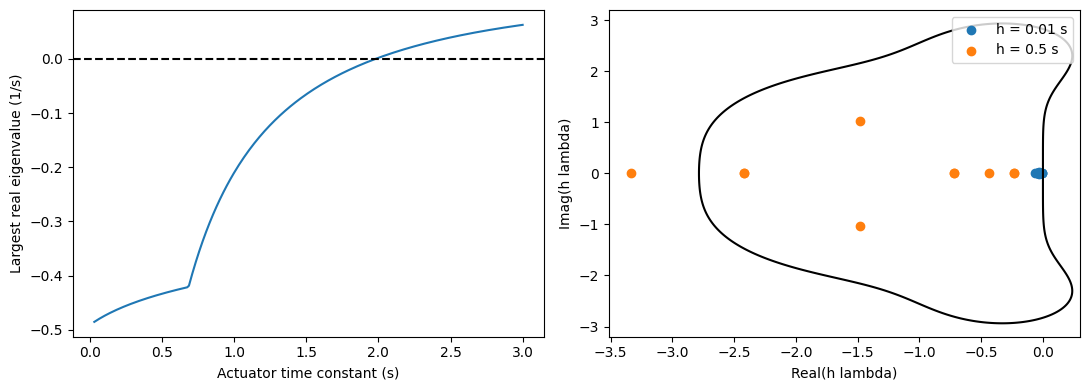

In [ ]:
def jacobian(P):
    A=np.zeros((10,10))
    A[:3,3:6]=np.eye(3)
    A[3:6,3:6]=-np.diag(P['D']/P['I'])
    A[3:6,6:]=P['B']/P['I'][:,None]
    if P['active']:
        A[6:,:3]=-H*Kp/P['tau']
        A[6:,3:6]=-H*Kd/P['tau']
    A[6:,6:]=-np.eye(4)/P['tau']
    return A

def stability(z):
    return 1+z+z**2/2+z**3/6+z**4/24

def step_limit(P):
    lam=np.linalg.eigvals(jacobian(P))
    if np.max(lam.real)>=0:return np.nan
    lo,hi=0.,1.
    while np.max(np.abs(stability(hi*lam)))<=1:hi*=2
    for _ in range(60):
        mid=(lo+hi)/2
        if np.max(np.abs(stability(mid*lam)))<=1:lo=mid
        else:hi=mid
    return lo

lam=np.linalg.eigvals(jacobian(P0))
eps=1.e-7;basis=np.eye(10)
Acheck=np.column_stack([(rhs(eps*e,0,P0)-rhs(-eps*e,0,P0))/(2*eps)
                        for e in basis])
assert np.allclose(Acheck,jacobian(P0),rtol=1.e-7,atol=1.e-8)
print('Nominal local step limit:',step_limit(P0))
print('Fast-actuator local step limit:',step_limit(parameters(tau=.05)))
assert np.max(lam.real)<0 and np.max(np.abs(stability(.01*lam)))<1
delays=np.linspace(.03,3.,250)
growth=np.array([np.max(np.linalg.eigvals(jacobian(parameters(tau=tau))).real)
                 for tau in delays])
print('First locally unstable delay in scan:',delays[np.flatnonzero(growth>=0)[0]])
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(delays,growth);ax[0].axhline(0,color='k',ls='--')
ax[0].set(xlabel='Actuator time constant (s)',ylabel='Largest real eigenvalue (1/s)')
xx,yy=np.meshgrid(np.linspace(-3.2,.3,250),np.linspace(-3.2,3.2,250))
ax[1].contour(xx,yy,np.abs(stability(xx+1j*yy)),levels=[1],colors='k')
for h in [.01,.5]:
    z=h*lam;ax[1].scatter(z.real,z.imag,label=f'h = {h} s')
ax[1].set(xlabel='Real(h lambda)',ylabel='Imag(h lambda)');ax[1].legend()
plt.tight_layout();plt.show();plt.close()

## Nonlinear convergence and cost

We compute an RK4 reference with $h_{\rm ref}=0.00125\ \mathrm{s}$ and compare solutions at matching times. The convergence error is the largest absolute difference in any Euler-angle component over the simulation, converted to degrees. This numerical error measure is separate from the total orientation error used for engineering performance below.

| Method | $h$ (s) | Maximum angle difference (deg) | Derivative evaluations |
|---|---:|---:|---:|
| Euler | 0.080 | $3.817\times10^{-1}$ | 300 |
| Euler | 0.020 | $9.030\times10^{-2}$ | 1200 |
| RK4 | 0.080 | $1.002\times10^{-4}$ | 1200 |
| RK4 | 0.040 | $4.919\times10^{-6}$ | 2400 |
| RK4 | 0.020 | $2.734\times10^{-7}$ | 4800 |
| RK4 | 0.010 | $1.605\times10^{-8}$ | 9600 |

Using $p_{\rm obs}=\log_2(e(h)/e(h/2))$, RK4 gives approximately 4.17 between $h=0.04$ and $0.02\ \mathrm{s}$. This is consistent with fourth-order convergence [6]. At 1200 derivative evaluations, RK4's angle difference is approximately 900 times smaller than Euler's. The reference is a numerical approximation; the independent exact and conservation checks above address correctness of the equations.

The final sweep repeats every production case using $h=0.005\ \mathrm{s}$ to verify the selected $0.01\ \mathrm{s}$ step across all studied parameter settings.

Euler  h=0.080  error=3.817e-01 deg  calls=300
Euler  h=0.040  error=1.838e-01 deg  calls=600
Euler  h=0.020  error=9.030e-02 deg  calls=1200
Euler  h=0.010  error=4.476e-02 deg  calls=2400
Euler  h=0.005  error=2.228e-02 deg  calls=4800
RK4    h=0.080  error=1.002e-04 deg  calls=1200
RK4    h=0.040  error=4.919e-06 deg  calls=2400
RK4    h=0.020  error=2.734e-07 deg  calls=4800
RK4    h=0.010  error=1.605e-08 deg  calls=9600
RK4    h=0.005  error=9.699e-10 deg  calls=19200
Full-model observed order: 4.169458722950673


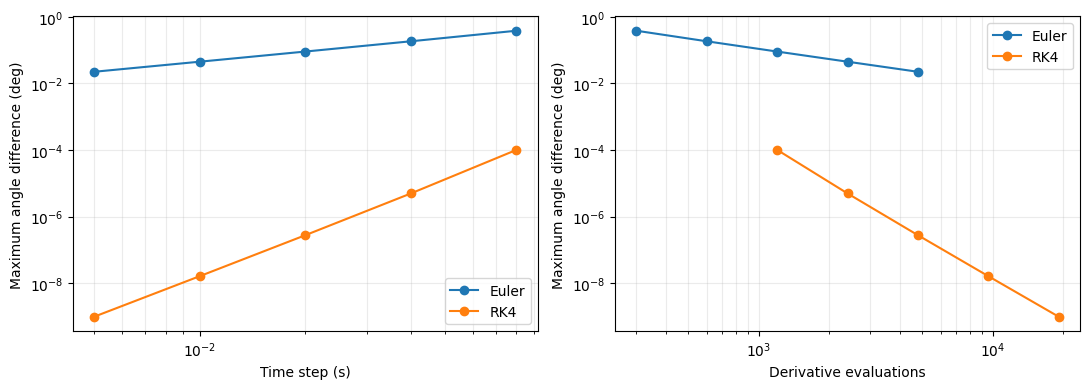

Corner tau=0.05, limit=25.0: 2.673e-07 deg
Corner tau=1.2, limit=5.0: 6.261e-09 deg


In [ ]:
tf,href=24.,.00125
tr,ur=integrate(lambda u,t:rhs(u,t,P0),u0,tf,href)
steps=np.array([.08,.04,.02,.01,.005])
angle_errors={};work={}
for method in ['Euler','RK4']:
    angle_errors[method]=[];work[method]=[]
    for h in steps:
        t,u=integrate(lambda u,t:rhs(u,t,P0),u0,tf,h,method)
        ref=ur[::int(round(h/href))]
        error=np.rad2deg(np.max(np.abs(u[:,:3]-ref[:,:3])))
        evaluations=int(round(tf/h))*(4 if method=='RK4' else 1)
        angle_errors[method].append(error);work[method].append(evaluations)
        print(f'{method:5s}  h={h:.3f}  error={error:.3e} deg  calls={evaluations}')
full_order=np.log2(angle_errors['RK4'][1]/angle_errors['RK4'][2])
print('Full-model observed order:',full_order)
assert 3.7<full_order<4.5
fig,ax=plt.subplots(1,2,figsize=(11,4))
for method in ['Euler','RK4']:
    ax[0].loglog(steps,angle_errors[method],'o-',label=method)
    ax[1].loglog(work[method],angle_errors[method],'o-',label=method)
ax[0].set(xlabel='Time step (s)',ylabel='Maximum angle difference (deg)')
ax[1].set(xlabel='Derivative evaluations',ylabel='Maximum angle difference (deg)')
for x in ax:x.legend();x.grid(True,which='both',alpha=.25)
plt.tight_layout();plt.show();plt.close()
for tau,limit in [(.05,25.),(1.2,5.)]:
    P=parameters(tau=tau,limit=limit)
    t,u=integrate(lambda u,t:rhs(u,t,P),u0,24.,.01)
    th,uh=integrate(lambda u,t:rhs(u,t,P),u0,24.,.005)
    error=np.rad2deg(np.max(np.abs(u[:,:3]-uh[::2,:3])))
    print(f'Corner tau={tau}, limit={limit}: {error:.3e} deg')
    assert error<.01

## Performance measures and nominal response

Define the total orientation error from the body-to-reference rotation matrix:

$$
\alpha(t)=\cos^{-1}\left(\frac{\operatorname{tr}R(t)-1}{2}\right).
$$

The numerical implementation clips the inverse-cosine argument to $[-1,1]$ to prevent roundoff from creating an invalid value.

Recovery requires both

$$
\alpha\le1^\circ,\qquad
\|\boldsymbol\omega\|_2\le1^\circ/\mathrm{s}.
$$

The reported settling time is the first sampled time after the last violation of either threshold, provided at least two seconds remain and both thresholds hold through the end of the run. This is a finite-horizon, sampled recovery measure.

Fin effort is the squared-deflection integral

$$
J_\delta=\int_0^{24}\sum_{j=1}^4\delta_j(t)^2\,dt,
$$

computed using the composite trapezoidal rule. Its units are $\mathrm{rad^2\,s}$; it is an actuator-use proxy, not mechanical energy. We also report peak total orientation error and peak absolute fin deflection.

| Nominal quantity | Computed value |
|---|---:|
| Settling time | $7.27\ \mathrm{s}$ |
| Peak total orientation error | $19.6311^\circ$ |
| Peak absolute fin deflection | $12.4014^\circ$ |
| Squared-deflection effort | $0.108652\ \mathrm{rad^2\,s}$ |

With zero fin commands and initially zero fin angles, the model does not recover; its final orientation error is approximately $65.70^\circ$. Because the model has rate damping but no static restoring moment, this comparison demonstrates the benefit of feedback within our model rather than the uncontrolled behavior of an actual Falcon 9.

The time histories document the transient. The orientation snapshots show rotation about the center of mass: solid segments indicate the longitudinal axis and dashed segments indicate a body-side direction. They do not show a flight trajectory.

Nominal [settling (s), peak error (deg), effort (rad^2 s), peak fin (deg)]:
[ 7.27       19.63106779  0.10865204 12.40138653]
Zero-command final angle error (deg): 65.70196690679313


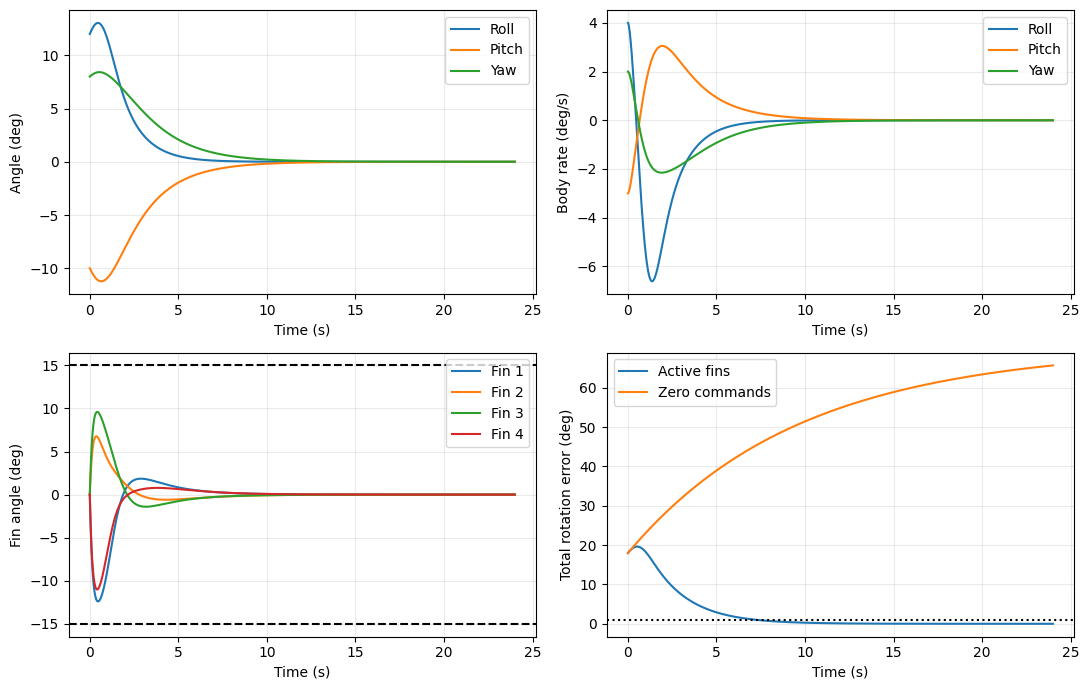

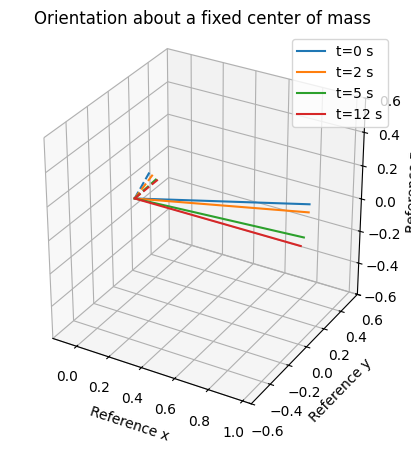

In [ ]:
def angle_error(u):
    matrices=np.array([rotation(angles) for angles in u[:,:3]])
    trace=np.trace(matrices,axis1=1,axis2=2)
    return np.arccos(np.clip((trace-1)/2,-1,1))

def measures(t,u,P):
    angle=angle_error(u)
    rate=np.linalg.norm(u[:,3:6],axis=1)
    outside=(angle>np.deg2rad(1))|(rate>np.deg2rad(1))
    bad=np.flatnonzero(outside)
    i=bad[-1]+1 if len(bad) else 0
    settling=t[i] if i<len(t) and t[-1]-t[i]>=2 else np.nan
    squared=np.sum(u[:,6:]**2,axis=1)
    effort=np.sum(.5*(squared[:-1]+squared[1:])*np.diff(t))
    return np.array([settling,np.rad2deg(np.max(angle)),effort,
                     np.rad2deg(np.max(np.abs(u[:,6:])))])

t,u=integrate(lambda u,t:rhs(u,t,P0),u0,24.,.01)
Poff=parameters(active=False)
_,uoff=integrate(lambda u,t:rhs(u,t,Poff),u0,24.,.01)
nominal=measures(t,u,P0)
print('Nominal [settling (s), peak error (deg), effort (rad^2 s), peak fin (deg)]:')
print(nominal)
print('Zero-command final angle error (deg):',np.rad2deg(angle_error(uoff)[-1]))
assert abs(nominal[0]-7.27)<.011
fig,ax=plt.subplots(2,2,figsize=(11,7))
for i,name in enumerate(['Roll','Pitch','Yaw']):
    ax[0,0].plot(t,np.rad2deg(u[:,i]),label=name)
    ax[0,1].plot(t,np.rad2deg(u[:,i+3]),label=name)
for j in range(4):ax[1,0].plot(t,np.rad2deg(u[:,j+6]),label=f'Fin {j+1}')
for sign in [-1,1]:ax[1,0].axhline(sign*15,color='k',ls='--')
ax[1,1].plot(t,np.rad2deg(angle_error(u)),label='Active fins')
ax[1,1].plot(t,np.rad2deg(angle_error(uoff)),label='Zero commands')
ax[1,1].axhline(1,color='k',ls=':')
for x,ylabel in zip(ax.flat,['Angle (deg)','Body rate (deg/s)',
                             'Fin angle (deg)','Total rotation error (deg)']):
    x.set(xlabel='Time (s)',ylabel=ylabel);x.legend();x.grid(alpha=.25)
plt.tight_layout();plt.show();plt.close()

fig=plt.figure(figsize=(7,5));ax=fig.add_subplot(111,projection='3d')
for time,color in zip([0.,2.,5.,12.],['C0','C1','C2','C3']):
    R=rotation(u[int(round(time/.01)),:3])
    nose=R@np.array([1.,0.,0.]);side=R@np.array([0.,.24,0.])
    ax.plot([0,nose[0]],[0,nose[1]],[0,nose[2]],color=color,label=f't={time:g} s')
    ax.plot([0,side[0]],[0,side[1]],[0,side[2]],'--',color=color)
ax.set(xlabel='Reference x',ylabel='Reference y',zlabel='Reference z',
       xlim=(-.15,1.05),ylim=(-.6,.6),zlim=(-.6,.6),
       title='Orientation about a fixed center of mass')
ax.set_box_aspect([1,1,1]);ax.legend();plt.show();plt.close()

## Fin-limit and actuator-response study

We vary

$$
\delta_{\max}\in\{5,7.5,10,12.5,15,20,25\}^\circ,
\qquad
\tau_a\in\{0.05,0.10,0.15,0.30,0.50,0.80,1.20\}\ \mathrm{s}.
$$

This gives 49 simulations with identical initial conditions, flight condition, gains, and nominal allocation. The heatmap cells represent the discrete sampled settings; their spacing is categorical rather than a continuous physical interpolation.

| $\tau_a$ (s) | $\delta_{\max}$ (deg) | Settling (s) | Peak error (deg) | $J_\delta$ ($\mathrm{rad^2\,s}$) |
|---:|---:|---:|---:|---:|
| 0.15 | 5 | 8.51 | 22.705 | 0.059903 |
| 0.15 | 15 | 7.27 | 19.631 | 0.108652 |
| 0.15 | 25 | 7.12 | 19.263 | 0.122578 |
| 0.80 | 15 | 7.93 | 21.014 | 0.131203 |
| 1.20 | 15 | 16.13 | 21.562 | 0.150578 |
| 1.20 | 5 | 19.54 | 26.153 | 0.084207 |

At the nominal actuator time constant, increasing the limit from $5^\circ$ to $15^\circ$ reduces settling time by 1.24 s. Increasing it again to $25^\circ$ saves only another 0.15 s, while increasing squared-deflection effort. This shows diminishing returns for additional travel with the fixed controller.

At a $15^\circ$ limit, increasing the time constant from 0.15 to 1.20 s increases settling time from 7.27 to 16.13 s. Sufficient fin travel therefore does not remove the effect of a slow actuator. All 49 cases recover, with settling times ranging from 7.10 to 19.54 s; these results establish performance only over this chosen grid and initial condition.

Every case is repeated at half the production step. The largest same-time Euler-angle change is $2.68\times10^{-7}$ deg, the largest settling-time change is 0.005 s, and the largest effort change is $4.27\times10^{-7}\ \mathrm{rad^2\,s}$. Recovery classifications are unchanged. The residual settling-time difference is consistent with sampling the threshold on different time grids.

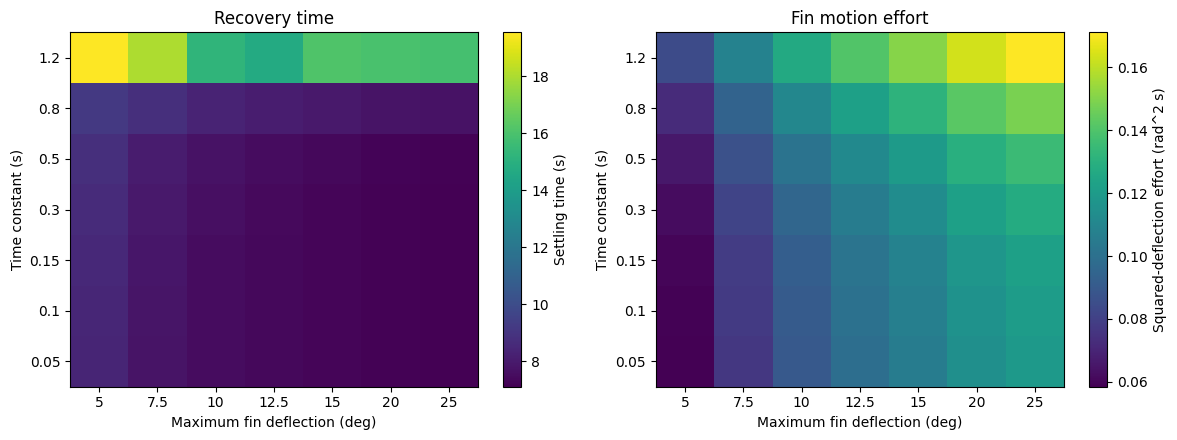

tau=0.15, limit=5: [ 8.51       22.70508032  0.05990279]
tau=0.15, limit=15: [ 7.27       19.63106779  0.10865204]
tau=0.15, limit=25: [ 7.12       19.26331435  0.12257785]
tau=0.80, limit=15: [ 7.93       21.01399978  0.13120251]
tau=1.20, limit=15: [16.13       21.56214538  0.1505775 ]
tau=1.20, limit=5: [19.54       26.15292219  0.08420721]
Recovered cases: 49 of 49
Maximum refinement changes [angle (deg), settling (s), effort (rad^2 s)]:
[2.67273632e-07 5.00000000e-03 4.26364214e-07]


In [ ]:
limits=np.array([5.,7.5,10.,12.5,15.,20.,25.])
taus=np.array([.05,.1,.15,.3,.5,.8,1.2])
results=np.zeros((len(taus),len(limits),4))
refinement=np.zeros((len(taus),len(limits),3))
for i,tau in enumerate(taus):
    for j,limit in enumerate(limits):
        P=parameters(tau=tau,limit=limit)
        t,u=integrate(lambda u,t:rhs(u,t,P),u0,24.,.01)
        results[i,j]=measures(t,u,P)
        th,uh=integrate(lambda u,t:rhs(u,t,P),u0,24.,.005)
        fine=measures(th,uh,P)
        refinement[i,j]=[
            np.rad2deg(np.max(np.abs(u[:,:3]-uh[::2,:3]))),
            abs(results[i,j,0]-fine[0]),abs(results[i,j,2]-fine[2])]
        assert refinement[i,j,0]<.01
        assert np.isfinite(results[i,j,0])==np.isfinite(fine[0])
        assert np.max(np.abs(u[:,6:]))<=P['limit']+1.e-8
        assert np.max(np.abs(u[:,1]))<np.deg2rad(60)
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
for x,index,title,label in zip(ax,[0,2],['Recovery time','Fin motion effort'],
    ['Settling time (s)','Squared-deflection effort (rad^2 s)']):
    im=x.imshow(np.ma.masked_invalid(results[:,:,index]),origin='lower',aspect='auto')
    x.set_xticks(range(len(limits)),[f'{v:g}' for v in limits])
    x.set_yticks(range(len(taus)),[f'{v:g}' for v in taus])
    x.set(xlabel='Maximum fin deflection (deg)',ylabel='Time constant (s)',title=title)
    fig.colorbar(im,ax=x,label=label)
plt.tight_layout();plt.show();plt.close()
for tau,limit in [(.15,5.),(.15,15.),(.15,25.),(.8,15.),(1.2,15.),(1.2,5.)]:
    i=np.flatnonzero(taus==tau)[0];j=np.flatnonzero(limits==limit)[0]
    print(f'tau={tau:.2f}, limit={limit:g}:',results[i,j,:3])
print('Recovered cases:',np.count_nonzero(np.isfinite(results[:,:,0])),'of 49')
print('Maximum refinement changes [angle (deg), settling (s), effort (rad^2 s)]:')
print(np.max(refinement,axis=(0,1)))

## Sensitivity to assumed force and inertia

Because the physical parameters are assumptions, we test one-at-a-time changes in fin-force effectiveness and inertia. A force multiplier scales $B$; an inertia multiplier scales all three principal inertias. The gains, damping coefficients, nominal allocator, and initial condition remain unchanged.

| Change | Factor | Settling (s) | $J_\delta$ ($\mathrm{rad^2\,s}$) |
|---|---:|---:|---:|
| Fin-force multiplier | 0.50 | 7.49 | 0.221 |
| Fin-force multiplier | 1.00 | 7.27 | 0.109 |
| Fin-force multiplier | 1.50 | 7.35 | 0.072 |
| Inertia multiplier | 0.75 | 7.47 | 0.080 |
| Inertia multiplier | 1.00 | 7.27 | 0.109 |
| Inertia multiplier | 1.25 | 7.09 | 0.138 |

Reduced force effectiveness requires more deflection effort to recover. The small nonmonotonic settling-time changes reflect use of one fixed controller across different plants. These are sensitivity experiments, not measured uncertainty bounds, and they do not establish that greater force or lower inertia always improves settling time.

In [ ]:
print('Parameter       factor   settling (s)   effort (rad^2 s)')
for name,values in [('force_scale',[.5,1.,1.5]),('inertia_scale',[.75,1.,1.25])]:
    for value in values:
        P=parameters(**{name:value})
        t,u=integrate(lambda u,t:rhs(u,t,P),u0,24.,.01)
        output=measures(t,u,P)
        print(f'{name:14s} {value:5.2f}    {output[0]:8.2f}      {output[2]:.3f}')

Parameter       factor   settling (s)   effort (rad^2 s)
force_scale     0.50        7.49      0.221
force_scale     1.00        7.27      0.109
force_scale     1.50        7.35      0.072
inertia_scale   0.75        7.47      0.080
inertia_scale   1.00        7.27      0.109
inertia_scale   1.25        7.09      0.138


## Conclusions

For the stated ten-state model, the nominal fins recover the attitude in 7.27 s. Larger allowable deflection improves recovery when travel is restrictive, with diminishing returns above the nominal limit. Increasing actuator lag can substantially delay recovery despite adequate travel. The parameter heatmaps and effort measurements answer the engineering question more directly than time histories alone.

The numerical evidence combines independently derived exact solutions, a torque-free conservation test, the expected convergence rate, local absolute-stability analysis, a cost comparison, and step refinement across every main sweep case. These checks support use of the implemented RK4 method for this study. They verify numerical behavior of the stated model; aerodynamic calibration and full-trajectory validation remain outside its scope.

## Group responsibilities and contribution allocation

**Proposed allocation: confirm completed work and actual percentages before submission.** Each member has a technical responsibility in rubric items 1--4. The percentages below assign work; they are not a record of work already completed.

| Member | Assigned technical responsibility | Planned share |
|---|---|---:|
| Bharat Rajesh | Physical premise, assumptions, inertia calculation, fin moment derivation, and unit/sign checks | 22% |
| Thomas Theodor | RK4 derivation, lecture-consistent error convention, stability analysis, and time-step justification | 25% |
| Jorgen Nelson | Time-stepping implementation, exact-solution and conservation checks, convergence and cost studies | 24% |
| Carlos Avila | Parameter sweep, sensitivity experiments, performance metrics, figures, and interpretation of results | 29% |
| **Total** | | **100%** |

## Acknowledgments: generative AI

ChatGPT (OpenAI) was used throughout project development: generating and refining the project idea; simplifying the physical model; selecting and explaining RK4; drafting and revising Python implementations; executing verification, convergence, and refinement checks; generating figures and numerical tables; checking references and source attribution; and preparing and revising report text and notebook LaTeX. AI assistance included substantial code and prose generation. Assumed physical parameters are identified separately from published Falcon 9 facts.

## Reproducibility and submission

This notebook is self-contained and requires Python 3, NumPy, and Matplotlib. Restart the kernel and run all cells in order to reproduce the verification checks, convergence studies, figures, parameter sweep, and sensitivity results. The sweep runs 49 cases at both production and refined time steps, so that cell takes longer than the other cells.

**Full-code URL:** `REPLACE_WITH_YOUR_ACCESSIBLE_NOTEBOOK_OR_REPOSITORY_LINK`.

The assignment requires a LaTeX-typeset PDF report plus a link to the complete code. The notebook contains the report content and code; it does not replace that PDF submission requirement. Confirm the contribution record and replace the code-link placeholder before submitting.

## References

Numbered citations in the text identify the supporting source. Model assumptions, controller choices, and results computed by this notebook are explicitly identified as our study choices and outputs.

[1] SpaceX. *Falcon 9*, vehicle overview and grid-fin description. Accessed October 29, 2026. https://new.spacex.com/vehicles/falcon-9 . Used for the rounded 3.7 m body diameter and four-fin reentry architecture.

[2] SpaceX. *Falcon User's Guide*, Version 8, March 2025. Section 2.3, p. 8, and Section 4.1.2, p. 15 (printed page numbers). https://www.spacex.com/assets/media/falcon-users-guide-2025-05-09.pdf . Used for first-stage grid-fin placement and roll/pitch/yaw axis naming. The guide's detailed 3.66 m diameter is consistent with the rounded 3.7 m overview value; this study uses the latter.

[3] J. Peraire and S. Widnall. *16.07 Dynamics, Lecture L28: 3D Rigid Body Dynamics: Equations of Motion; Euler's Equations*. MIT OpenCourseWare, Fall 2009, pp. 1--3, especially Eqs. (5) and (9)--(11). https://ocw.mit.edu/courses/16-07-dynamics-fall-2009/5e1d8699338146e5127080b880b906d6_MIT16_07F09_Lec28.pdf . Used for angular-momentum balance and principal-axis rigid-body dynamics.

[4] H. Smith. *Aircraft Flight Mechanics: Summary of the Equations of Motion*, subsection "Attitude rate due to a body rate." https://www.aircraftflightmechanics.com/Linearisation/EoMs/Summary.html . Accessed October 29, 2026. Used for the 3-2-1 Euler-angle/body-rate relations.

[5] A. Goza. *AE 370: Lecture 10, IVPs and One-Step Methods*. Fall 2026, Eq. (8). Course-provided lecture material. Used for the integral formulation, explicit Euler, and four-stage RK4.

[6] A. Goza. *AE 370: Lecture 11, Multi-step Methods and Truncation Error*. Fall 2026, especially the truncation-error definition and convention following Eq. (5). Course-provided lecture material. Used for Taylor error analysis and the normalized truncation-error convention.

[7] A. Goza. *AE 370: Lecture 12, Absolute Stability*. Fall 2026. Course-provided lecture material. Used for the scalar test equation, stability functions, linearized eigenvalue checks, and stable convergence.

[8] A. Goza. *AE 370: Lecture 13, Stiff IVPs*. Fall 2026. Course-provided lecture material. Used for the interpretation of fast modes and explicit-method stability restrictions.